(33300, 30, 14)
(33300, 30, 1)
The shape of last layer encoder is (None, 8, 16)
Epoch 1/2
235/235 [==============================] - 2s 8ms/step - loss: 0.0468 - val_loss: 0.0111
Epoch 2/2
1041/1041 [==============================] - 1s 1ms/step


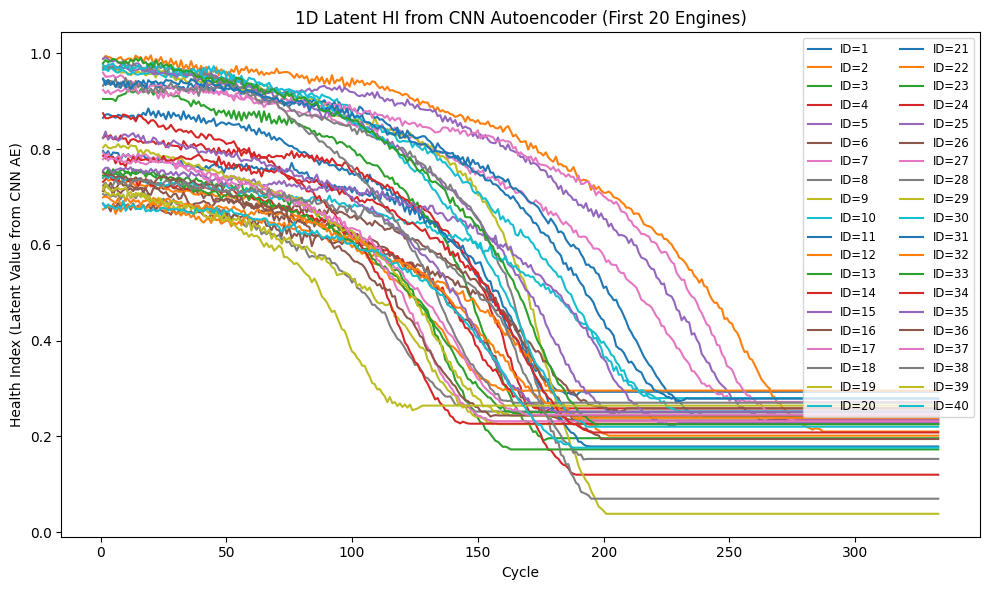

In [18]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'utility')))
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"  
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}

from sklearn.preprocessing      import MinMaxScaler
from keras.models               import Model
from keras.layers               import Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Flatten, Reshape, ZeroPadding1D, Concatenate, Lambda, Multiply, Minimum, Maximum, LSTM, Masking
from keras.layers               import GlobalAveragePooling1D, RepeatVector
from preProcessingDataTurbofan  import PreProcessData
from matpilotDraw               import MatPlot

import tensorflow           as tf
import numpy                as np
import pandas               as pd
import matplotlib.pyplot    as plt
import random
import warnings


warnings.filterwarnings('ignore') 
tf.random.set_seed(1)
np.random.seed(1)
random.seed(1)

useRUL          = False
epochTrain      = 2
sysEpoch        = 20
hiSelectionMode = "min"

# -----------------------------
# Load and prepare data
# -----------------------------
column_names = [    "id",   "cycle",    "setting1", "setting2", "setting3",
                    "s1",   "s2",       "s3",       "s4",       "s5",       "s6",   "s7",   "s8",   "s9",   "s10",
                    "s11",  "s12",      "s13",      "s14",      "s15",      "s16",  "s17",  "s18",  "s19",  "s20",  "s21"
                ]
df              = pd.read_csv('~/Desktop/Dropbox/codeData/turbofanEngines/data/df_train.txt', delim_whitespace=True, header=None, names=column_names)
df["rul"]       = df.groupby('id',sort=False)['cycle'].transform(lambda x: x.max() - x)         # Get RUL
sameLengthDf    = PreProcessData.padDataForTheSameTrajectoryLength(df)  
# -----------------------------
# Initialize variables
# -----------------------------
def dataHandling(df, idName = 'id', sensors_used=None):
    if sensors_used is None: 
        sensors_used    = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']
    
    window_size     = 30  # Fixed sequence length
    X_windows       = []
    engine_ids      = []
    start_cycles    = []

    # Build sliding windows from each engine
    for eng_id in df[idName].unique():
        # df_eng      = df[df[idName] == eng_id].sort_values('cycle')
        df_eng      = df[df[idName] == eng_id]
        data_eng    = df_eng[sensors_used].values
        for start in range(0, len(data_eng) - window_size + 1):
            window = data_eng[start : start + window_size]
            X_windows.append(window)
            engine_ids.append(eng_id)
            start_cycles.append(start + 1)

    X_windows = np.array(X_windows)  # (N, 30, 14)
    print(X_windows.shape)
    # Normalize
    N, seq_len, num_feats   = X_windows.shape
    X_flat                  = X_windows.reshape(N * seq_len, num_feats)
    scaler                  = MinMaxScaler()
    X_flat_scaled           = scaler.fit_transform(X_flat)
    X_scaled                = X_flat_scaled.reshape(N, seq_len, num_feats)
    return X_scaled, engine_ids, start_cycles, seq_len, num_feats

X_scaled, engine_ids, start_cycles, seq_len, num_feats  = dataHandling(sameLengthDf)
y_rul, _, _, _, _                                       = dataHandling(sameLengthDf, sensors_used=['rul'])  # Get RUL data
y_rul   = y_rul[:,-1,:]  # Get last value of each sequence
# -----------------------------
# Encoder block
# -----------------------------
inputs      = Input(shape=(seq_len, num_feats))
# m1          = Masking(mask_value=0.0)(inputs)  # if you used 0.0 as pad
x           = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x           = MaxPooling1D(2, padding='same')(x)
x           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x           = GlobalAveragePooling1D()(lastAELayer)
latent      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# -----------------------------
# Decoder block
# -----------------------------
x           = Dense((seq_len // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seq_len // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(num_feats, 3, activation='linear', padding='same', name='reconstruction')(x)  # Shape: (30, 14)

# -----------------------------
# Use RUL as label
# -----------------------------
if useRUL:
    rulLayer2   = LSTM(16, return_sequences=True)(lastAELayer)
    rulLayer3   = LSTM(3, return_sequences=False)(rulLayer2)
    rulLayer4   = Concatenate(axis=-1)([rulLayer3, latent])

    rul         = Dense(1, activation='linear', name="RUL_Output")(rulLayer4)
    cnn_ae = Model(inputs, outputs=[decoded, rul])
    cnn_ae.compile(optimizer='adam', 
                   loss={'reconstruction': 'mse', 'RUL_Output': 'mse'},
                   loss_weights={'reconstruction': 1.0, 'RUL_Output': 0.5})  # adjust weights as needed
else:
    cnn_ae = Model(inputs, decoded)
    cnn_ae.compile(optimizer='adam', loss='mse')


if useRUL:
    cnn_ae.fit(X_scaled, {'reconstruction': X_scaled, 'RUL_Output': y_rul},
               epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)
else:
    cnn_ae.fit(X_scaled, X_scaled, epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)


# Extract latent HI values
encoder = Model(    inputs  =   cnn_ae.input,
                    outputs =   [cnn_ae.get_layer('lastAELayer').output, 
                                 cnn_ae.get_layer('latent').output],
                                name="encoder_submodel")

_, hi_values   = encoder.predict(X_scaled)
hi_values      = hi_values.flatten()  # Flatten to 1D array
# Normalize HI (optional)
hi_values = (hi_values - hi_values.min()) / (hi_values.max() - hi_values.min())

# Build dataframe for plotting
df_hi = pd.DataFrame({
    'id': engine_ids,
    'cycle': start_cycles,
    'HI': hi_values
})

# Plot first 20 engines
plt.figure(figsize=(10, 6))
for eng_id in df_hi['id'].unique()[:40]:
    df_eng = df_hi[df_hi['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()


### Create the data system

In [2]:
# from keras.preprocessing.sequence import pad_sequences

def createSystemData(inData, numberOfTrajectories=300, mode = "max"):
   
    rawData         = inData
    # --------------------------
    # Group the data into ID and
    # initiate the values
    # --------------------------
    grouped_data    = {k: v for k, v in rawData.groupby("id")}                                                          # Pre-group `rawData` by 'id' for O(1) lookup
    createdData     = {}                                                                                                # Initialize dictionary for cases
    # --------------------------
    # Create system data
    # --------------------------
    selected_ids    = np.array([np.random.choice(np.arange(1, 101), size=3, replace=False) for _ in range(numberOfTrajectories)])     # Generate 400 sets of 3 unique trajectory IDs per iteration
    
    comp1_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 0])], ignore_index=True) 
    comp2_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 1])], ignore_index=True) 
    comp3_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 2])], ignore_index=True)                    # Fetch data from grouped dictionary (guaranteed unique per iteration)

    dfRul           = pd.DataFrame(columns=["rul", "trajectoryID"])                                                                                  # Initialize RUL dataframe
    if mode == 'min':
        dfRul["rul"] = pd.concat([comp1_df["rul"], comp2_df["rul"], comp3_df["rul"]], axis=1).min(axis=1)
    elif mode == 'max':
        dfRul["rul"] = pd.concat([comp1_df["rul"], comp2_df["rul"], comp3_df["rul"]], axis=1).max(axis=1)
    else:
        dfRul["rul"] = comp1_df["rul"].combine(comp2_df["rul"], max).combine(comp3_df["rul"], min)
    
    dfRul["trajectoryID"] = comp1_df["trajectoryID"]      # Add trajectoryID to RUL data

    testRUL                = pd.DataFrame(columns=["rul", "trajectoryID"])   
    testRUL["minRUL"]      = pd.concat([comp1_df["rul"], comp2_df["rul"], comp3_df["rul"]], axis=1).min(axis=1)
    testRUL["maxRUL"]      = pd.concat([comp1_df["rul"], comp2_df["rul"], comp3_df["rul"]], axis=1).max(axis=1)
    testRUL["linearRUL"]   = comp1_df["rul"].combine(comp2_df["rul"], max).combine(comp3_df["rul"], min)
    testRUL["trajectoryID"] = comp1_df["trajectoryID"]
    # aiLogger.debug(createdData)
    return comp1_df, comp2_df, comp3_df, dfRul,testRUL


# ------------------------------
# Create system data
# ------------------------------
    
# print("-===============================",sameLengthDf)                                                                             # Copy original dataframe 
comp1, comp2, comp3, dfRul, testRUL        = createSystemData(sameLengthDf, numberOfTrajectories=300, mode=hiSelectionMode)  # Create system data

# print(comp1.head)
# print(comp2.head)
# print(dfRul)

# X_scaled1, engine_ids1, start_cycles1, _, _ = dataHandling(sameLengthDf,   idName='id')
X_scaled1, engine_ids1, start_cycles1, _, _ = dataHandling(comp1,   idName='trajectoryID')
X_scaled2, engine_ids2, start_cycles2, _, _ = dataHandling(comp2,   idName='trajectoryID')
X_scaled3, engine_ids3, start_cycles3, _, _ = dataHandling(comp3,   idName='trajectoryID')
sysRUL, _, _, _, _                          = dataHandling(dfRul,   idName='trajectoryID', sensors_used=['rul'])  # Get RUL data
sysRUL = sysRUL[:,-1,:]



(99900, 30, 14)
(99900, 30, 14)
(99900, 30, 14)
(99900, 30, 1)


In [3]:
testX =  X_scaled3
print(testX.shape)

_, hi_values1   = encoder.predict(testX)
hi_values1      = hi_values1.flatten()  # Flatten to 1D array
print(hi_values1.shape)

(99900, 30, 14)
3122/3122 [==============================] - 4s 1ms/step
(99900,)


In [4]:
# Build dataframe for plotting
df_hi = pd.DataFrame({
    'id'    : engine_ids1,
    'cycle' : start_cycles1,
    'HI'    : hi_values1,
    # "sysRUL": sysRUL
})

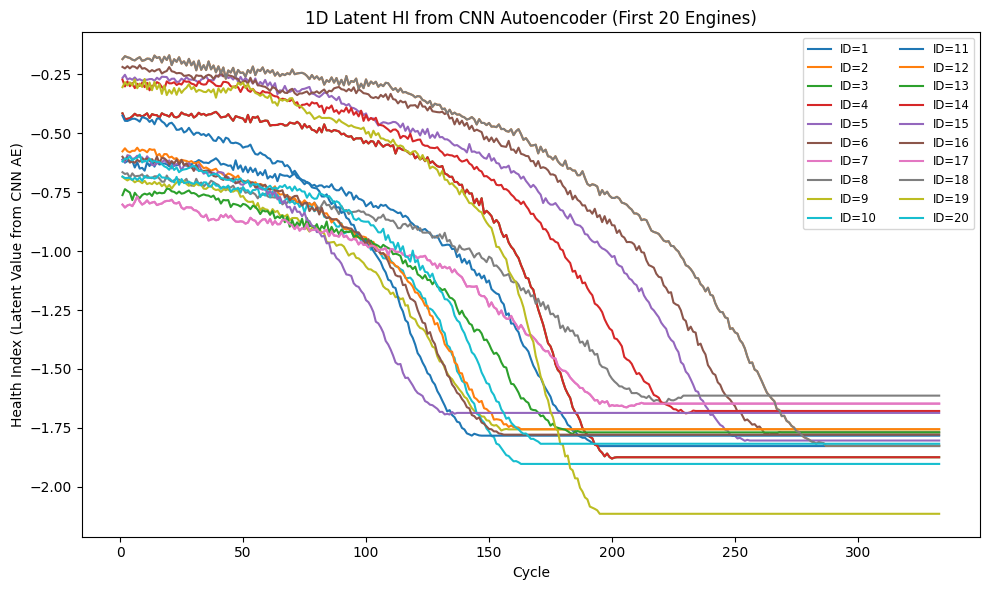

In [5]:
plt.figure(figsize=(10, 6))
for eng_id in df_hi['id'].unique()[:20]:
    df_eng = df_hi[df_hi['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()


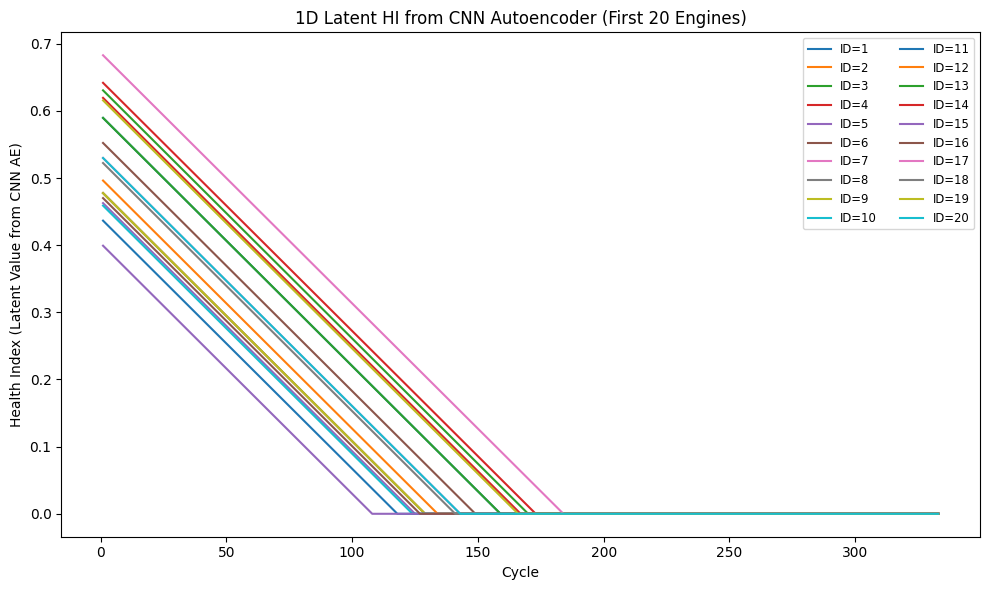

In [6]:
plt.figure(figsize=(10, 6))
for eng_id in df_hi['id'].unique()[:20]:
    rul     = sysRUL[df_hi['id'] == eng_id]
    df_eng  = df_hi[df_hi['id'] == eng_id]
    plt.plot(df_eng['cycle'], rul, label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()

### System model

In [7]:
encoder.summary()
for layer in encoder.layers:
    layer.trainable = False

Model: "encoder_submodel"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 30, 14)]          0         
                                                                 
 conv1d (Conv1D)             (None, 30, 32)            1376      
                                                                 
 max_pooling1d (MaxPooling1D  (None, 15, 32)           0         
 )                                                               
                                                                 
 conv1d_1 (Conv1D)           (None, 15, 16)            1552      
                                                                 
 lastAELayer (MaxPooling1D)  (None, 8, 16)             0         
                                                                 
 global_average_pooling1d (G  (None, 16)               0         
 lobalAveragePooling1D)                           

In [8]:
def selection_entropy_loss(y_true, y_pred):
    """
    y_pred: hiMatrixOutput -> shape (None, 3)
    We ignore y_true because we don't have a label for it.
    This returns the negative sum(p * log p).
    """
    # Add a small constant (1e-10) inside the log to avoid log(0).
    # The shape of this expression is (batch_size,).
    neg_entropy = -tf.reduce_sum(y_pred * tf.math.log(y_pred + 1e-10), axis=-1)
    return neg_entropy


In [9]:
input1              = Input(shape=(seq_len, num_feats))
input2              = Input(shape=(seq_len, num_feats))
input3              = Input(shape=(seq_len, num_feats))

inputRUL1, inputHI1 = encoder(input1)
inputRUL2, inputHI2 = encoder(input2)
inputRUL3, inputHI3 = encoder(input3)

# inputRUL1   = Input(shape=(8, 16),     name = "lastLayerAEComponent1")
# inputRUL2   = Input(shape=(8, 16),     name = "lastLayerAEComponent2")
# inputRUL3   = Input(shape=(8, 16),     name = "lastLayerAEComponent3")

# inputHI1    = Input(shape=(1,),     name = "compHI1")
# inputHI2    = Input(shape=(1,),     name = "compHI2")
# inputHI3    = Input(shape=(1,),     name = "compHI3")


flatInRUL1          = Flatten()(inputRUL1)  # Shape: (32, 40)
flatInRUL2          = Flatten()(inputRUL2)  # Shape: (32, 40)
flatInRUL3          = Flatten()(inputRUL3)  # Shape: (32, 40)
hiSelectionInput    = Concatenate(axis=-1)([flatInRUL1, flatInRUL2, flatInRUL3])

print(f"The shape of hiSelectionInput {hiSelectionInput.shape}")
# ------------------------------
# Create the HI selection matrix
# ------------------------------
x                   = Dense(24, activation="relu")(hiSelectionInput)
x                   = Dense(16, activation="relu")(x)
selection_logits    = Dense(3, activation=None, name="Selection_Logits")(x)
hiMatrixOutput      = Lambda(lambda x: tf.nn.softmax(x / 1), name="Selection_Output")(selection_logits)  # Softmax with τ=0.1 for sharper selection
print(f"The shape of multiplied matrix {hiMatrixOutput.shape}")

# ------------------------------
# Create min, max and linear HI
# ------------------------------
concatenatedHiInput = Concatenate(axis=-1)([inputHI1, inputHI2, inputHI3])
minSysHi            = Minimum()([inputHI1, inputHI2, inputHI3])
maxSysHi            = Maximum()([inputHI1, inputHI2, inputHI3]) 
linearSysHi         = Minimum()([Maximum()([inputHI1, inputHI2]), inputHI3])


print(f"The shape of min, max and linear HI {minSysHi.shape, maxSysHi.shape, linearSysHi.shape}")

sysConcatenatedHi   = tf.keras.layers.Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, maxSysHi, linearSysHi])
# sysConcatenatedHi   = tf.keras.layers.Concatenate(axis=-1, name="sysConcatenatedHi")([maxSysHi, linearSysHi])

print(f"The shape after concatenation {sysConcatenatedHi.shape}")
selected_HI         = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])

print(f"The shape after multiplying with mask {selected_HI.shape}")
sysHi               = Lambda(lambda x: tf.reduce_sum(x, axis=-1, keepdims=True), name="Final_HI")(selected_HI)            # Final HI (ensuring only one HI contributes to output)
# sysHi               = linearSysHi

print(f"The shape of HI after reducing dimension {sysHi.shape}")
# ------------------------------
# RUL
# ------------------------------
concatenatedRULInput = Concatenate(axis=-1)([inputRUL1, inputRUL2, inputRUL3])
print(f"The shape of concatenatedRULInput {concatenatedRULInput.shape}")
# concatenatedRULInput = Concatenate(axis=-1)([inputRUL1, inputRUL2])
rulLayer1   = LSTM(32, return_sequences=True)(concatenatedRULInput)
rulLayer2   = LSTM(16, return_sequences=True)(rulLayer1)
rulLayer3   = LSTM(3, return_sequences=False)(rulLayer2)
rulLayer4   = Concatenate(axis=-1)([rulLayer3, sysHi])
rul         = tf.keras.layers.Dense(1, activation='linear', name = "RUL_Output")(rulLayer4)

# Create the model
sysModel = Model(inputs=[input1, input2, input3], outputs=[hiMatrixOutput, sysHi,rul])

sysModel.compile(optimizer  =       'adam',
                loss        =   {   "Selection_Output"  : selection_entropy_loss,
                                    "Final_HI"          : "mse",
                                    "RUL_Output"        : "mse"},
                loss_weights=   {   "Selection_Output"  : 0.1,  # e.g. a small coefficient
                                    "Final_HI"          : 0.0,  # no label for HI => set to 0 or 0.01 if you want
                                    "RUL_Output"        : 1.0},      
                )

sysModel.summary()

dummy_sel = np.zeros_like(sysRUL)
sysModel.fit([X_scaled1, X_scaled2, X_scaled3], [dummy_sel,dummy_sel,sysRUL], epochs=sysEpoch, batch_size=128, validation_split=0.1, verbose=1)


The shape of hiSelectionInput (None, 384)
The shape of multiplied matrix (None, 3)
The shape of min, max and linear HI (TensorShape([None, 1]), TensorShape([None, 1]), TensorShape([None, 1]))
The shape after concatenation (None, 3)
The shape after multiplying with mask (None, 3)
The shape of HI after reducing dimension (None, 1)
The shape of concatenatedRULInput (None, 8, 48)
Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_2 (InputLayer)           [(None, 30, 14)]     0           []                               
                                                                                                  
 input_3 (InputLayer)           [(None, 30, 14)]     0           []                               
                                                                                                  
 input_4 (

In [10]:
_, hi_values1   = encoder.predict(X_scaled1)
hi_values1      = hi_values1.flatten()  # Flatten to 1D array

_, hi_values2   = encoder.predict(X_scaled2)
hi_values2      = hi_values2.flatten()  # Flatten to 1D array

_, hi_values3   = encoder.predict(X_scaled3)
hi_values3      = hi_values3.flatten()  # Flatten to 1D array

[hiMatrixOutput, sysHi, rul] = sysModel.predict([X_scaled1, X_scaled2, X_scaled3])


3122/3122 [==============================] - 17s 5ms/step


In [11]:
# Build dataframe for plotting
df_hi = pd.DataFrame({
    'id'    : engine_ids1,
    'cycle' : start_cycles1,
    'HI1'    : hi_values1,
    'HI2'    : hi_values2,
    'HI3'    : hi_values3,
    'sysHI'  : sysHi.flatten(),
    # "sysRUL": sysRUL
})

(99900, 30, 3)


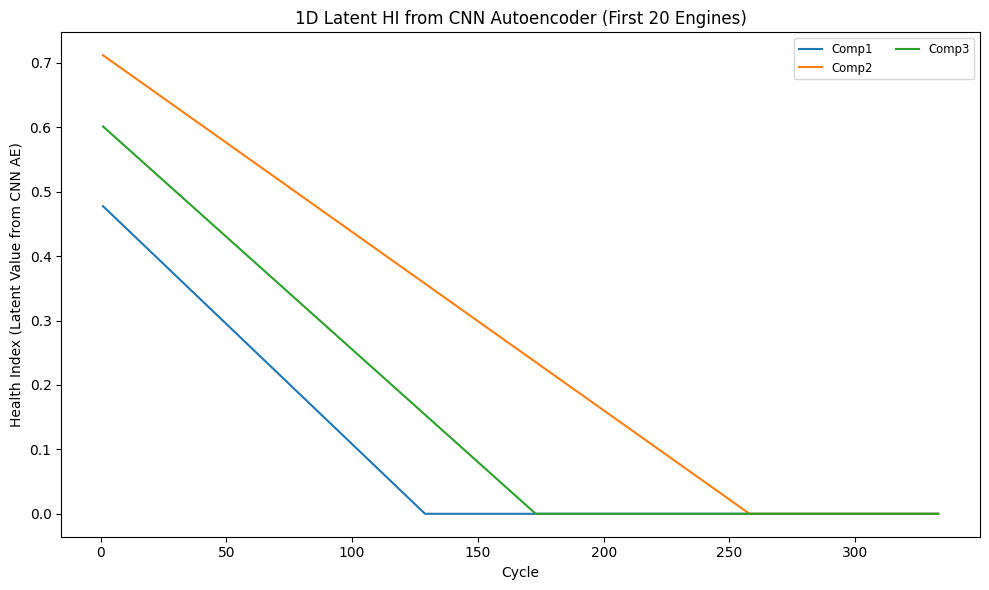

In [12]:
sysTestRUL, _, _, _, _        = dataHandling(testRUL,   idName='trajectoryID', sensors_used=['minRUL', 'maxRUL', 'linearRUL'])  # Get RUL data

minRUL      = sysTestRUL[:,-1,0]
maxRUL      = sysTestRUL[:,-1,1]
linearRUL   = sysTestRUL[:,-1,2]

drawTrajectories = 1
plt.figure(figsize=(10, 6))
# for eng_id in df_hi['id'].unique()[:drawTrajectories]:
eng_id =2

minRulEng       = minRUL[df_hi['id'] == eng_id]
maxRulEng       = maxRUL[df_hi['id'] == eng_id]
linearRulEng    = linearRUL[df_hi['id'] == eng_id]
df_eng  = df_hi[df_hi['id'] == eng_id]
plt.plot(df_eng['cycle'], minRulEng, label="Comp1")
plt.plot(df_eng['cycle'], maxRulEng, label="Comp2")
plt.plot(df_eng['cycle'], linearRulEng, label="Comp3")
    # plt.plot(df_eng['cycle'], df_eng["sysHI"], label="Sys")
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()


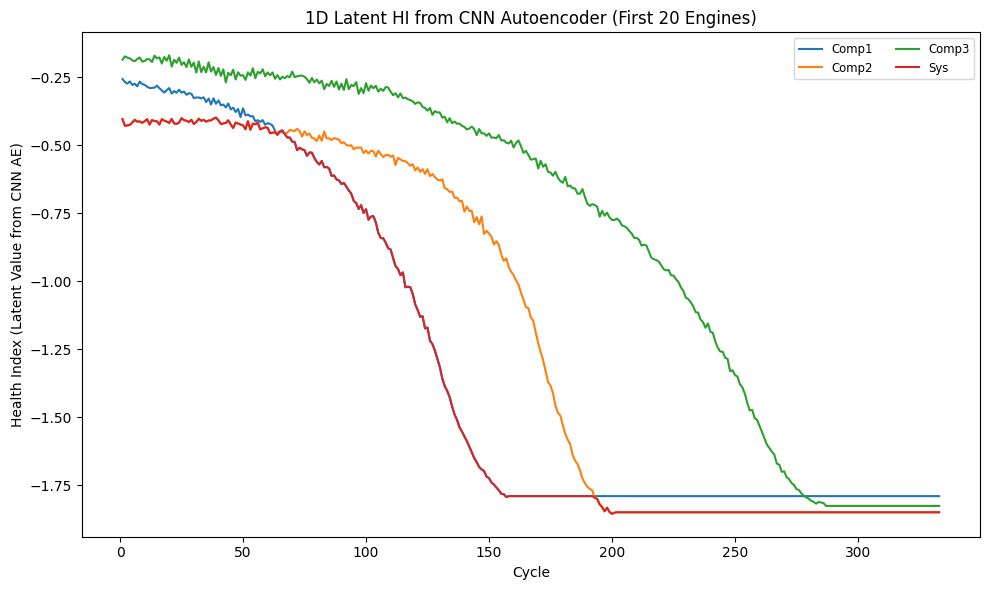

In [13]:
drawTrajectories = 1
plt.figure(figsize=(10, 6))
# for eng_id in df_hi['id'].unique()[:drawTrajectories]:
eng_id =2
df_eng  = df_hi[df_hi['id'] == eng_id]
plt.plot(df_eng['cycle'], df_eng["HI1"], label="Comp1")
plt.plot(df_eng['cycle'], df_eng["HI2"], label="Comp2")
plt.plot(df_eng['cycle'], df_eng["HI3"], label="Comp3")
plt.plot(df_eng['cycle'], df_eng["sysHI"], label="Sys")
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()

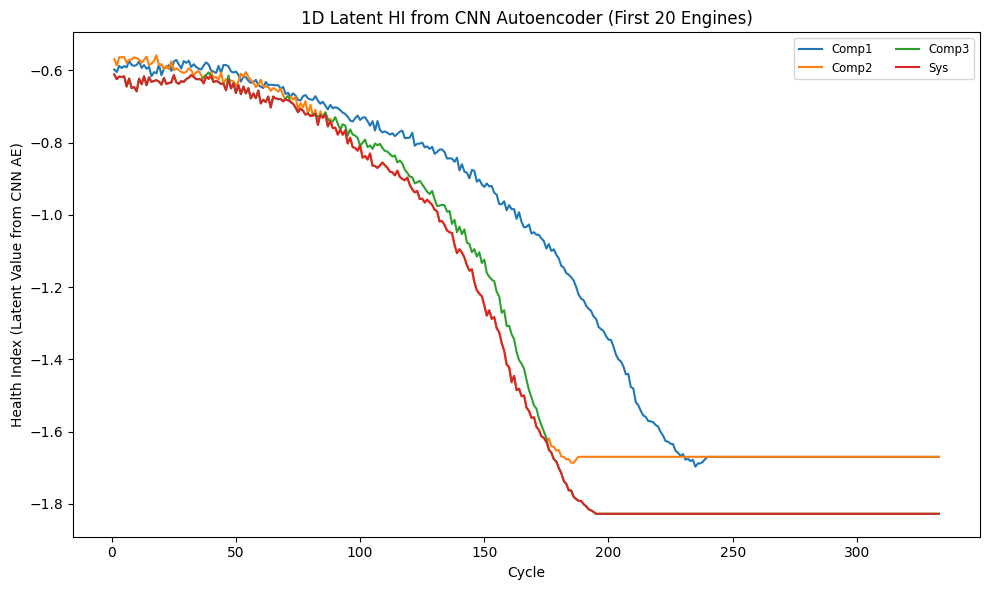

In [14]:
drawTrajectories = 1
plt.figure(figsize=(10, 6))
for eng_id in df_hi['id'].unique()[:drawTrajectories]:
    df_eng  = df_hi[df_hi['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng["HI1"], label="Comp1")
    plt.plot(df_eng['cycle'], df_eng["HI2"], label="Comp2")
    plt.plot(df_eng['cycle'], df_eng["HI3"], label="Comp3")
    plt.plot(df_eng['cycle'], df_eng["sysHI"], label="Sys")
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()

In [15]:
testRUL

,rul,trajectoryID,minRUL,maxRUL,linearRUL
0,NaN,1,187.0,239.0,194.0
1,NaN,1,186.0,238.0,193.0
2,NaN,1,185.0,237.0,192.0
3,NaN,1,184.0,236.0,191.0
4,NaN,1,183.0,235.0,190.0
...,...,...,...,...,...
108595,NaN,300,0.0,0.0,0.0
108596,NaN,300,0.0,0.0,0.0
108597,NaN,300,0.0,0.0,0.0
108598,NaN,300,0.0,0.0,0.0




In [16]:
import matplotlib.pyplot as plt
import math

drawTrajectories = 300
num_cols = 5  # number of plots per row
num_rows = math.ceil(drawTrajectories / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(df_hi['id'].unique()[:drawTrajectories]):
    ax = axes[i]
    df_eng = df_hi[df_hi['id'] == eng_id]
    
    ax.plot(df_eng['cycle'], df_eng["HI1"], label="Comp1")
    ax.plot(df_eng['cycle'], df_eng["HI2"], label="Comp2")
    ax.plot(df_eng['cycle'], df_eng["HI3"], label="Comp3")
    ax.plot(df_eng['cycle'], df_eng["sysHI"], label="Sys")
    
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()
